In [1]:
import numpy as np, rasterio, matplotlib.pyplot as plt
from matplotlib.colors import LightSource
import geopandas as gpd

SL    = "../data/constructs/sledG_torch_pitedge_pitpit_2010.npz"
DEM   = "../data/rasters/canwell_domainlong_elev2010_5m.tif"   # grid the graph was built on
SLOPE = "../data/outlines/ncanwell_longslope_nolap.gpkg"
BASIN = "../data/outlines/ncanwell_longbasin_nolap.gpkg"

sl = np.load(SL, allow_pickle=True)
node_rc = sl["node_rc"].astype(int)       # (N_s,2) [row,col]
pit_idx = sl["node_pit_idx"].astype(int)  # tree id = each node's pit (torch index)
e_tree  = sl["e_tree"]                     # (2,E) directed downslope

with rasterio.open(DEM) as src:
    dem = src.read(1).astype(float); T = src.transform; H, W = dem.shape
dem[dem < -1e30] = np.nan
extent  = (T.c, T.c + W*T.a, T.f + H*T.e, T.f)                  # left,right,bottom,top
node_xy = np.c_[T.c + (node_rc[:,1]+0.5)*T.a, T.f + (node_rc[:,0]+0.5)*T.e]

# permuted 20-color palette so spatially adjacent trees differ
rng = np.random.default_rng(7)
uniq = np.unique(pit_idx)
remap = np.zeros(pit_idx.max()+1, int); remap[uniq] = rng.integers(0, 20, uniq.size)
node_color = remap[pit_idx]

ls = LightSource(azdeg=315, altdeg=45)
hs = ls.hillshade(np.nan_to_num(dem, nan=np.nanmin(dem)), vert_exag=2.0)
print("grid", (H, W), "| trees", uniq.size, "| nodes", len(pit_idx))

grid (1545, 2710) | trees 522 | nodes 851862


In [2]:
# helper cell for scale bar and north arrow

from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm, matplotlib.patheffects as pe

def scalebar(ax, length_m, label, loc="lower right"):
    ax.add_artist(AnchoredSizeBar(ax.transData, length_m, label, loc, pad=0.4,
                  color="k", frameon=True, size_vertical=length_m*0.02,
                  fontproperties=fm.FontProperties(size=9)))

def north_arrow(ax, x=0.50, y=0.88):
    ax.annotate("N", xy=(x, y+0.07), xytext=(x, y-0.03), xycoords="axes fraction",
                ha="center", va="center", fontsize=13, fontweight="bold",
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.6))

In [3]:
# selection cell

pits = np.unique(pit_idx)                       # the 522 real pit ids
pit_sizes = np.bincount(pit_idx)[pits]          # their tree sizes

target1 = 100                                     # size that shows branching without becoming a blob
target2 = 30000
pick1 = pits[np.argsort(np.abs(pit_sizes - target1))[:1]]
pick2 = pits[np.argsort(np.abs(pit_sizes - target2))[:1]]
pick = pick = np.concatenate([pick1, pick2])           # two trees, small + large
print("picked pits:", pick.tolist(),
      "| sizes:", np.bincount(pit_idx)[pick].tolist())

picked pits: [499802, 538805] | sizes: [100, 30311]


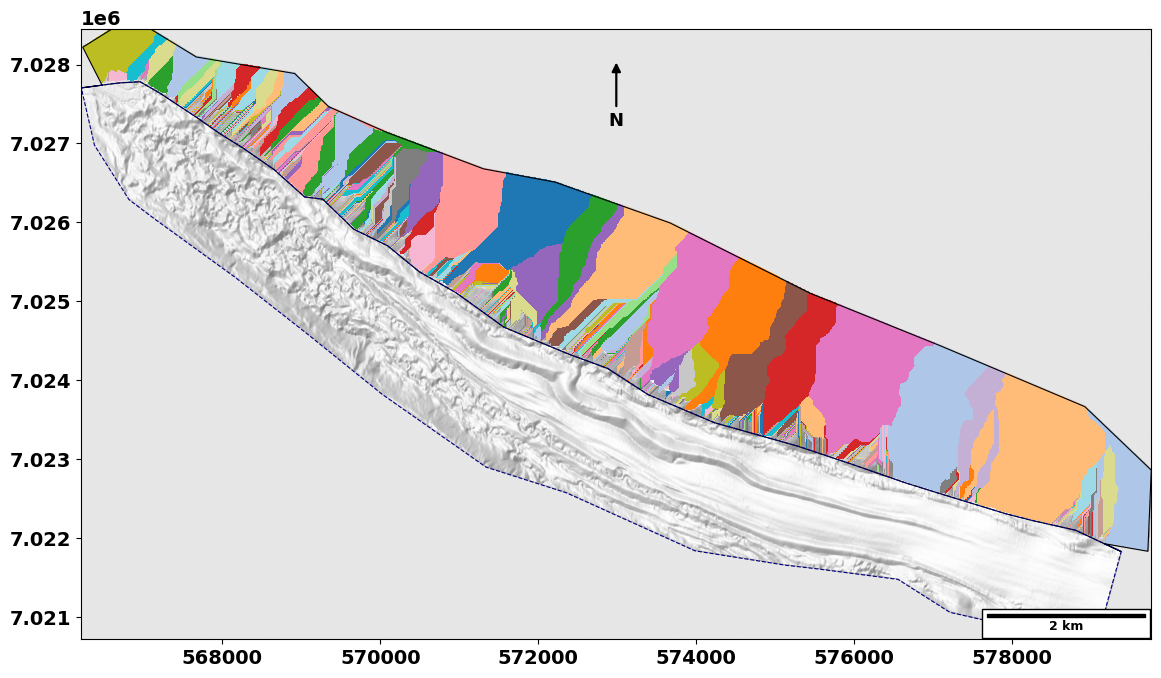

In [7]:
img = np.full((H, W), np.nan)
img[node_rc[:,0], node_rc[:,1]] = node_color
img = np.ma.masked_invalid(img)

# Set global font size and bold weight
plt.rcParams.update({
    'font.size': 14,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'figure.titleweight': 'bold'
})

fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(hs,  cmap="gray", extent=extent, origin="upper", alpha=0.55, zorder=0)
ax.imshow(img, cmap=plt.get_cmap("tab20", 20), vmin=0, vmax=19,
          extent=extent, origin="upper", interpolation="nearest", zorder=1)
gpd.read_file(SLOPE).boundary.plot(ax=ax, color="k",    lw=0.8, zorder=2)
gpd.read_file(BASIN).boundary.plot(ax=ax, color="navy", lw=0.8, ls="--", zorder=2)
#ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
#ax.set_title(f"Drainage threshold trees — Canwell north slope ({uniq.size} trees)")

scalebar(ax, 2000, "2 km", loc="lower right")
north_arrow(ax)
'''
for k, p in enumerate(pick, 1):
    x, y = node_xy[p]
    ax.scatter(x, y, s=150, marker="*", c="gold", ec="k", lw=1.2, zorder=5)
    ax.annotate(f"pit {k}", (x, y), xytext=(9, 9), textcoords="offset points",
                fontsize=11, fontweight="bold", color="k", zorder=6,
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
'''

plt.tight_layout()
# plt.savefig("../figures/thresholdtrees2010_nopit.png", dpi=220, bbox_inches="tight")
plt.show()

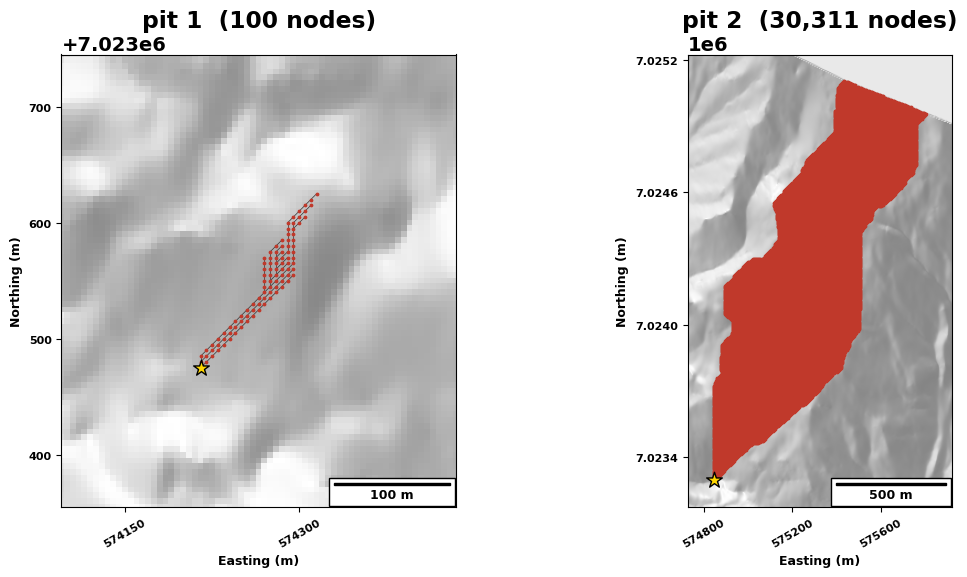

In [51]:
from matplotlib.collections import LineCollection
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(1, len(pick), figsize=(12, 6))
for k, (ax, pit) in enumerate(zip(np.atleast_1d(axes), pick), 1):
    sel = np.where(pit_idx == pit)[0]
    m = np.isin(e_tree[0], sel) & np.isin(e_tree[1], sel)
    seg = np.stack([node_xy[e_tree[0][m]], node_xy[e_tree[1][m]]], 1)
    ax.imshow(hs, cmap="gray", extent=extent, origin="upper", alpha=0.5, zorder=0)
    ax.add_collection(LineCollection(seg, colors="#333", linewidths=0.5, zorder=1))
    ax.scatter(node_xy[sel,0], node_xy[sel,1], s=3, c="#c0392b", zorder=2)
    ax.scatter(*node_xy[pit], s=140, marker="*", c="gold", ec="k", zorder=3)
    xs, ys = node_xy[sel,0], node_xy[sel,1]
    ax.set_xlim(xs.min()-120, xs.max()+120); ax.set_ylim(ys.min()-120, ys.max()+120)
    ax.set_aspect("equal"); ax.set_title(f"pit {k}  ({sel.size:,} nodes)")
    ax.xaxis.set_major_locator(MaxNLocator(3)); ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.tick_params(axis="x", rotation=30, labelsize=8); ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("Easting (m)", fontsize=9); ax.set_ylabel("Northing (m)", fontsize=9)
    span = max(xs.max()-xs.min(), ys.max()-ys.min())
    sb = next(v for v in (100, 200, 500, 1000, 2000) if v >= span/4)
    scalebar(ax, sb, f"{sb/1000:g} km" if sb >= 1000 else f"{sb:g} m", loc="lower right")
plt.tight_layout()
# plt.savefig("../figures/two_trees2010.png", dpi=220, bbox_inches="tight")
plt.show()

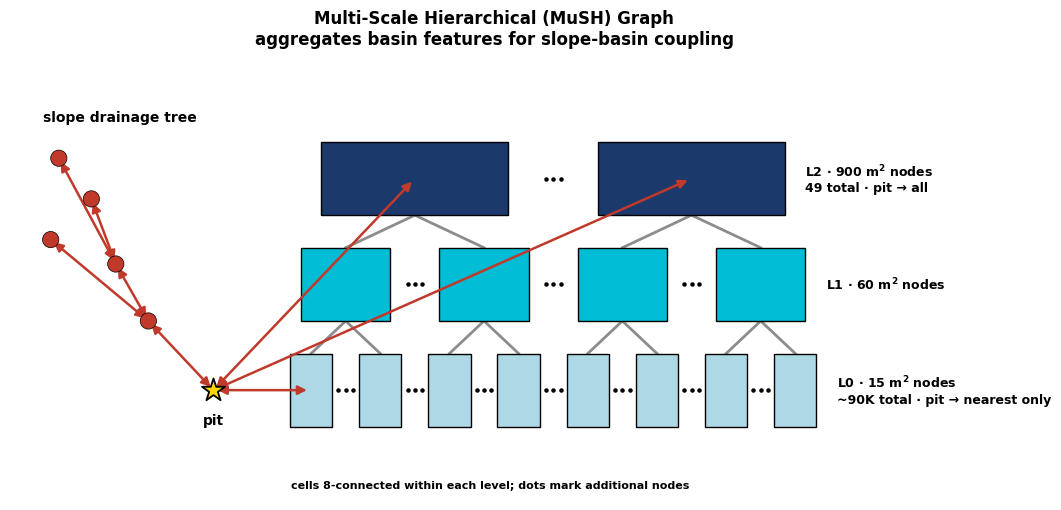

In [67]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyArrowPatch

RED, GRAY = "#c0392b", "0.55"
BLUES = ["#add8e6", "#00bcd4", "#1b3a6b"]     # light blue, cyan, dark blue

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.set_aspect("equal"); ax.axis("off")
ax.set_xlim(-0.3, 11.6); ax.set_ylim(-0.9, 4.6)

# ---------- basin pyramid: aligned cells (8 / 4 / 2) with gap-dots ----------
X0, rowh = 3.4, 0.9
spec = [  # (n, pitch, draw_w, y, label)
    (8, 0.85, 0.52, 0.0, "L0 · 15 m$^2$ nodes\n~90K total · pit → nearest only"),
    (4, 1.70, 1.10, 1.3, "L1 · 60 m$^2$ nodes"),
    (2, 3.40, 2.30, 2.6, "L2 · 900 m$^2$ nodes\n49 total · pit → all"),
]
centers = {}
for Li, (n, p, w, y, lab) in enumerate(spec):
    first = X0 + (p - 0.85) / 2            # keep levels concentric
    cx = [first + i*p for i in range(n)]
    for x in cx:
        ax.add_patch(Rectangle((x - w/2, y), w, rowh, facecolor=BLUES[Li],
                               edgecolor="k", lw=1.0, zorder=2))
    # gap-dots between shown cells = "grid continues"
    for a, b in zip(cx[:-1], cx[1:]):
        gx, sp = (a + b) / 2, min(0.09, (b - a) * 0.11)
        ax.scatter([gx - sp, gx, gx + sp], [y + rowh/2]*3, s=5, c="k", zorder=3)
    centers[Li] = [(x, y + rowh/2) for x in cx]
    ax.text(cx[-1] + w/2 + 0.25, y + rowh/2, lab, ha="left", va="center",
            fontsize=9, fontweight="bold", color="k")

# containment (gray, thick, no arrow)
for Li in (0, 1):
    for i, (x, _) in enumerate(centers[Li]):
        px, _ = centers[Li+1][i // 2]
        ax.plot([x, px], [spec[Li][3] + rowh, spec[Li+1][3]], color=GRAY, lw=2.0, zorder=1)

# ---------- slope drainage tree (red, bidirectional) ----------
tree = {"a": (0.3, 3.3), "b": (0.7, 2.8), "c": (0.2, 2.3), "m1": (1.0, 2.0), "m2": (1.4, 1.3)}
tedges = [("a","m1"), ("b","m1"), ("c","m2"), ("m1","m2"), ("m2","pit")]
pit = (2.2, 0.45)
def biarrow(p0, p1, lw=1.8):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="<|-|>", color=RED, lw=lw,
                                 mutation_scale=13, shrinkA=3, shrinkB=3, zorder=4))
for u, v in tedges:
    biarrow(tree[u], pit if v == "pit" else tree[v])
for x, y in tree.values():
    ax.add_patch(Circle((x, y), 0.10, facecolor=RED, edgecolor="k", lw=0.5, zorder=5))
ax.scatter(*pit, s=300, marker="*", c="gold", ec="k", lw=1.3, zorder=6)
ax.text(pit[0], pit[1]-0.42, "pit", ha="center", fontsize=10, fontweight="bold", color="k")
ax.text(0.1, 3.75, "slope drainage tree", fontsize=10, fontweight="bold", color="k")

# ---------- pit fans (same red, bidirectional) ----------
biarrow(pit, centers[0][0])                 # nearest L0
for c in centers[2]:                        # all L2
    biarrow(pit, c)

ax.set_title("Multi-Scale Hierarchical (MuSH) Graph\naggregates basin features for slope-basin coupling", fontsize=12, color="k")
ax.text(5.6, -0.75, "cells 8-connected within each level; dots mark additional nodes",
        fontsize=8, color="k", ha="center")
plt.tight_layout()
# plt.savefig("../figures/mushgraph.png", dpi=220, bbox_inches="tight")
plt.show()